In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from IPython.display import display

# Enter the uploaded CSV file path here
FILE_PATH = "/content/StudentPerformanceFactors.csv"

# Load the dataset
df = pd.read_csv(FILE_PATH)

# Display basic confirmation
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (6607, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [2]:
print("First five records:")
display(df.head())

print("\nLast five records:")
display(df.tail())

print("\nNumber of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

First five records:


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70



Last five records:


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
6602,25,69,High,Medium,No,7,76,Medium,Yes,1,High,Medium,Public,Positive,2,No,High School,Near,Female,68
6603,23,76,High,Medium,No,8,81,Medium,Yes,3,Low,High,Public,Positive,2,No,High School,Near,Female,69
6604,20,90,Medium,Low,Yes,6,65,Low,Yes,3,Low,Medium,Public,Negative,2,No,Postgraduate,Near,Female,68
6605,10,86,High,High,Yes,6,91,High,Yes,2,Low,Medium,Private,Positive,3,No,High School,Far,Female,68
6606,15,67,Medium,Low,Yes,9,94,Medium,Yes,0,Medium,Medium,Public,Positive,4,No,Postgraduate,Near,Male,64



Number of rows: 6607
Number of columns: 20

Column names:
['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender', 'Exam_Score']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours            

### Dataset Description

The Student Performance Factors dataset is obtained from Kaggle. It contains information about students' study habits, attendance, parental involvement, educational resources, lifestyle factors and examination performance.

The dataset contains numerical and categorical attributes. The `Exam_Score` column represents the student's examination score and can be considered a possible target variable for a future prediction task.

**Dataset name:** Student Performance Factors

**Source:** [Kaggle – Student Performance Factors](https://www.kaggle.com/datasets/lainguyn123/student-performance-factors)

**File type:** CSV

In [3]:
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical columns:")
print(numerical_columns)

print("\nCategorical columns:")
print(categorical_columns)

print("\nNumber of numerical columns:", len(numerical_columns))
print("Number of categorical columns:", len(categorical_columns))

print("\nPossible target variable: Exam_Score")

Numerical columns:
['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity', 'Exam_Score']

Categorical columns:
['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']

Number of numerical columns: 7
Number of categorical columns: 13

Possible target variable: Exam_Score


In [4]:
print("Summary statistics of numerical columns:")
display(df.describe())

print("\nSummary statistics of categorical columns:")
display(df.describe(include="object"))

Summary statistics of numerical columns:


,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000



Summary statistics of categorical columns:


,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Motivation_Level,Internet_Access,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender
count,6607,6607,6607,6607,6607,6607,6529,6607,6607,6607,6517,6540,6607
unique,3,3,2,3,2,3,3,2,3,2,3,3,2
top,Medium,Medium,Yes,Medium,Yes,Low,Medium,Public,Positive,No,High School,Near,Male
freq,3362,3319,3938,3351,6108,2672,3925,4598,2638,5912,3223,3884,3814


In [5]:
missing_count = df.isnull().sum()

missing_percentage = (missing_count / len(df)) * 100

missing_table = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage": missing_percentage.round(2)
})

print("Missing value analysis:")
display(missing_table)

print("Total missing values:", df.isnull().sum().sum())

Missing value analysis:


,Missing Values,Missing Percentage
Hours_Studied,0,0.00
Attendance,0,0.00
Parental_Involvement,0,0.00
Access_to_Resources,0,0.00
Extracurricular_Activities,0,0.00
Sleep_Hours,0,0.00
Previous_Scores,0,0.00
Motivation_Level,0,0.00
Internet_Access,0,0.00
Tutoring_Sessions,0,0.00


Total missing values: 235


In [6]:
# Preserve the original dataset
cleaned_df = df.copy()

# Remove extra spaces and standardise repeated whitespace
for column in cleaned_df.select_dtypes(include="object").columns:
    cleaned_df[column] = (
        cleaned_df[column]
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
    )

print("Category consistency check:")

for column in cleaned_df.select_dtypes(include="object").columns:
    print("\n", column)
    print(cleaned_df[column].value_counts(dropna=False))

Category consistency check:

 Parental_Involvement
Parental_Involvement
Medium    3362
High      1908
Low       1337
Name: count, dtype: int64

 Access_to_Resources
Access_to_Resources
Medium    3319
High      1975
Low       1313
Name: count, dtype: int64

 Extracurricular_Activities
Extracurricular_Activities
Yes    3938
No     2669
Name: count, dtype: int64

 Motivation_Level
Motivation_Level
Medium    3351
Low       1937
High      1319
Name: count, dtype: int64

 Internet_Access
Internet_Access
Yes    6108
No      499
Name: count, dtype: int64

 Family_Income
Family_Income
Low       2672
Medium    2666
High      1269
Name: count, dtype: int64

 Teacher_Quality
Teacher_Quality
Medium    3925
High      1947
Low        657
NaN         78
Name: count, dtype: int64

 School_Type
School_Type
Public     4598
Private    2009
Name: count, dtype: int64

 Peer_Influence
Peer_Influence
Positive    2638
Neutral     2592
Negative    1377
Name: count, dtype: int64

 Learning_Disabilities
Learning_

In [7]:
duplicate_count = cleaned_df.duplicated().sum()

print("Duplicate records found:", duplicate_count)

# Remove exact duplicate rows
cleaned_df = cleaned_df.drop_duplicates()

print("Duplicate records after removal:", cleaned_df.duplicated().sum())
print("Shape after duplicate handling:", cleaned_df.shape)

Duplicate records found: 0
Duplicate records after removal: 0
Shape after duplicate handling: (6607, 20)


In [8]:
# Identify column types after cleaning
numerical_columns = cleaned_df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = cleaned_df.select_dtypes(exclude=np.number).columns.tolist()

# Fill missing numerical values using median
for column in numerical_columns:
    if cleaned_df[column].isnull().any():
        cleaned_df[column] = cleaned_df[column].fillna(
            cleaned_df[column].median()
        )

# Fill missing categorical values using mode
for column in categorical_columns:
    if cleaned_df[column].isnull().any():
        mode_value = cleaned_df[column].mode()

        if not mode_value.empty:
            cleaned_df[column] = cleaned_df[column].fillna(mode_value[0])
        else:
            cleaned_df[column] = cleaned_df[column].fillna("Unknown")

print("Missing values handled successfully!")

print("\nRemaining missing values:")
print(cleaned_df.isnull().sum())

print("\nTotal remaining missing values:",
      cleaned_df.isnull().sum().sum())

Missing values handled successfully!

Remaining missing values:
Hours_Studied                 0
Attendance                    0
Parental_Involvement          0
Access_to_Resources           0
Extracurricular_Activities    0
Sleep_Hours                   0
Previous_Scores               0
Motivation_Level              0
Internet_Access               0
Tutoring_Sessions             0
Family_Income                 0
Teacher_Quality               0
School_Type                   0
Peer_Influence                0
Physical_Activity             0
Learning_Disabilities         0
Parental_Education_Level      0
Distance_from_Home            0
Gender                        0
Exam_Score                    0
dtype: int64

Total remaining missing values: 0


In [9]:
print("Dataset shape after cleaning:", cleaned_df.shape)

print("\nData types after cleaning:")
print(cleaned_df.dtypes)

print("\nRemaining missing values:",
      cleaned_df.isnull().sum().sum())

print("\nRemaining duplicates:",
      cleaned_df.duplicated().sum())

display(cleaned_df.head())

Dataset shape after cleaning: (6607, 20)

Data types after cleaning:
Hours_Studied                  int64
Attendance                     int64
Parental_Involvement          object
Access_to_Resources           object
Extracurricular_Activities    object
Sleep_Hours                    int64
Previous_Scores                int64
Motivation_Level              object
Internet_Access               object
Tutoring_Sessions              int64
Family_Income                 object
Teacher_Quality               object
School_Type                   object
Peer_Influence                object
Physical_Activity              int64
Learning_Disabilities         object
Parental_Education_Level      object
Distance_from_Home            object
Gender                        object
Exam_Score                     int64
dtype: object

Remaining missing values: 0

Remaining duplicates: 0


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [10]:
print("Frequency distribution of Parental Involvement:")

display(
    cleaned_df["Parental_Involvement"].value_counts()
)

print("\nFrequency distribution of School Type:")

display(
    cleaned_df["School_Type"].value_counts()
)

Frequency distribution of Parental Involvement:


,count
Parental_Involvement,
Medium,3362
High,1908
Low,1337



Frequency distribution of School Type:


,count
School_Type,
Public,4598
Private,2009


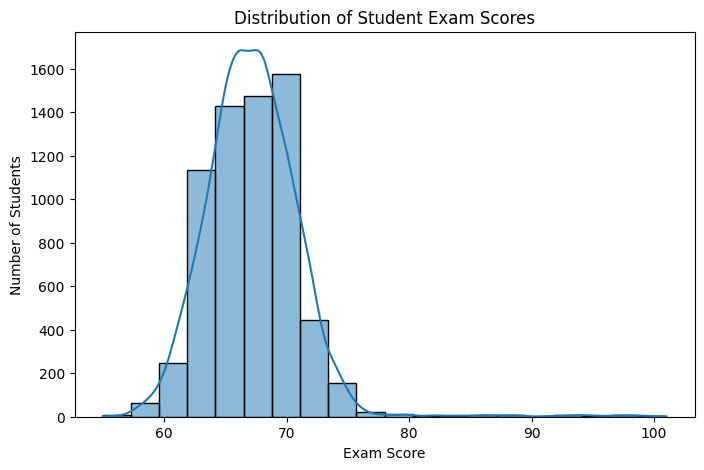

In [11]:
plt.figure(figsize=(8, 5))

sns.histplot(data=cleaned_df, x="Exam_Score", bins=20, kde=True)

plt.title("Distribution of Student Exam Scores")
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")

plt.show()

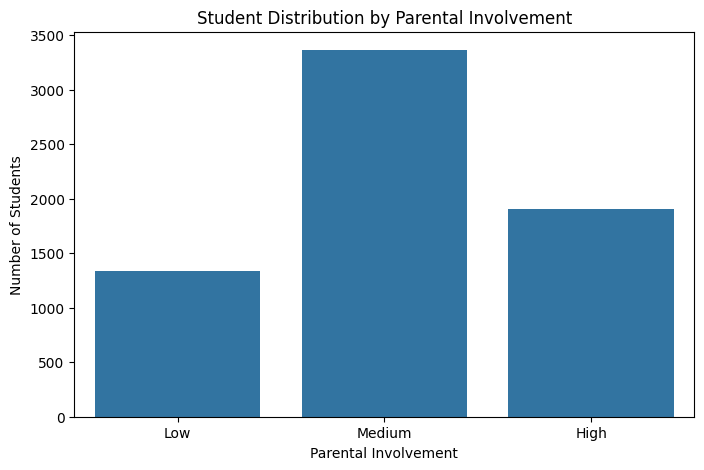

In [12]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=cleaned_df,
    x="Parental_Involvement",
    order=["Low", "Medium", "High"]
)

plt.title("Student Distribution by Parental Involvement")
plt.xlabel("Parental Involvement")
plt.ylabel("Number of Students")

plt.show()

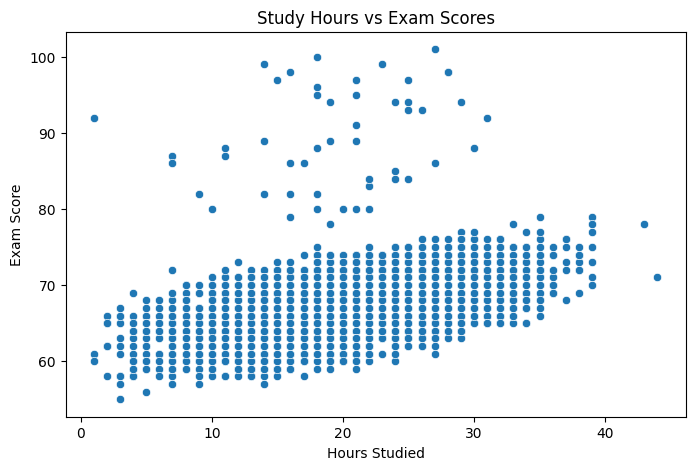

In [13]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=cleaned_df,
    x="Hours_Studied",
    y="Exam_Score"
)

plt.title("Study Hours vs Exam Scores")
plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")

plt.show()

### Observations from EDA

1. The histogram shows the distribution and variation of students' examination scores.
2. The parental involvement bar chart shows the number of students in each parental involvement category.
3. The scatter plot helps examine the relationship between study hours and examination scores.

These visualisations provide an initial understanding of the dataset and its features.

In [14]:
# Identify categorical columns
categorical_columns = cleaned_df.select_dtypes(
    include="object"
).columns.tolist()

print("Categorical columns before encoding:")
print(categorical_columns)

# Apply one-hot encoding
encoded_df = pd.get_dummies(
    cleaned_df,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

print("\nShape before encoding:", cleaned_df.shape)
print("Shape after encoding:", encoded_df.shape)

print("\nEncoded dataset preview:")
display(encoded_df.head())

Categorical columns before encoding:
['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']

Shape before encoding: (6607, 20)
Shape after encoding: (6607, 28)

Encoded dataset preview:


,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score,Parental_Involvement_Low,Parental_Involvement_Medium,Access_to_Resources_Low,...,Teacher_Quality_Medium,School_Type_Public,Peer_Influence_Neutral,Peer_Influence_Positive,Learning_Disabilities_Yes,Parental_Education_Level_High School,Parental_Education_Level_Postgraduate,Distance_from_Home_Moderate,Distance_from_Home_Near,Gender_Male
0,23,84,7,73,0,3,67,1,0,0,...,1,1,0,1,0,1,0,0,1,1
1,19,64,8,59,2,4,61,1,0,0,...,1,1,0,0,0,0,0,1,0,0
2,24,98,7,91,2,4,74,0,1,0,...,1,1,1,0,0,0,1,0,1,1
3,29,89,8,98,1,4,71,1,0,0,...,1,1,0,0,0,1,0,1,0,1
4,19,92,6,65,3,4,70,0,1,0,...,0,1,1,0,0,0,0,0,1,0


In [15]:
prepared_df = encoded_df.copy()

# Exclude the target and possible identifier columns
target_column = "Exam_Score"

id_columns = [
    column for column in numerical_columns
    if column.lower() == "id"
    or column.lower().endswith("_id")
]

columns_to_scale = [
    column for column in numerical_columns
    if column in prepared_df.columns
    and column != target_column
    and column not in id_columns
]

scaler = StandardScaler()

prepared_df[columns_to_scale] = scaler.fit_transform(
    prepared_df[columns_to_scale]
)

print("Standardisation completed successfully!")

print("\nColumns scaled:")
print(columns_to_scale)

print("\nTarget column kept unchanged:", target_column)

display(prepared_df.head())

Standardisation completed successfully!

Columns scaled:
['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity']

Target column kept unchanged: Exam_Score


,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score,Parental_Involvement_Low,Parental_Involvement_Medium,Access_to_Resources_Low,...,Teacher_Quality_Medium,School_Type_Public,Peer_Influence_Neutral,Peer_Influence_Positive,Learning_Disabilities_Yes,Parental_Education_Level_High School,Parental_Education_Level_Postgraduate,Distance_from_Home_Moderate,Distance_from_Home_Near,Gender_Male
0,0.504942,0.348375,-0.019796,-0.143800,-1.213934,0.031411,67,1,0,0,...,1,1,0,1,0,1,0,0,1,1
1,-0.162822,-1.383736,0.661399,-1.116110,0.411451,1.001199,61,1,0,0,...,1,1,0,0,0,0,0,1,0,0
2,0.671882,1.560853,-0.019796,1.106313,0.411451,1.001199,74,0,1,0,...,1,1,1,0,0,0,1,0,1,1
3,1.506587,0.781403,0.661399,1.592469,-0.401242,1.001199,71,1,0,0,...,1,1,0,0,0,1,0,1,0,1
4,-0.162822,1.041220,-0.700990,-0.699406,1.224144,1.001199,70,0,1,0,...,0,1,1,0,0,0,0,0,1,0


In [16]:
print("FINAL DATASET VERIFICATION")

print("\nFinal number of rows:", prepared_df.shape[0])
print("Final number of columns:", prepared_df.shape[1])

print("\nRemaining missing values:",
      prepared_df.isnull().sum().sum())

print("Remaining duplicate records:",
      prepared_df.duplicated().sum())

print("\nFinal dataset sample:")
display(prepared_df.head())

FINAL DATASET VERIFICATION

Final number of rows: 6607
Final number of columns: 28

Remaining missing values: 0
Remaining duplicate records: 0

Final dataset sample:


,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score,Parental_Involvement_Low,Parental_Involvement_Medium,Access_to_Resources_Low,...,Teacher_Quality_Medium,School_Type_Public,Peer_Influence_Neutral,Peer_Influence_Positive,Learning_Disabilities_Yes,Parental_Education_Level_High School,Parental_Education_Level_Postgraduate,Distance_from_Home_Moderate,Distance_from_Home_Near,Gender_Male
0,0.504942,0.348375,-0.019796,-0.143800,-1.213934,0.031411,67,1,0,0,...,1,1,0,1,0,1,0,0,1,1
1,-0.162822,-1.383736,0.661399,-1.116110,0.411451,1.001199,61,1,0,0,...,1,1,0,0,0,0,0,1,0,0
2,0.671882,1.560853,-0.019796,1.106313,0.411451,1.001199,74,0,1,0,...,1,1,1,0,0,0,1,0,1,1
3,1.506587,0.781403,0.661399,1.592469,-0.401242,1.001199,71,1,0,0,...,1,1,0,0,0,1,0,1,0,1
4,-0.162822,1.041220,-0.700990,-0.699406,1.224144,1.001199,70,0,1,0,...,0,1,1,0,0,0,0,0,1,0


In [17]:
output_file = "/content/student_performance_prepared.csv"

prepared_df.to_csv(output_file, index=False)

print("Prepared dataset saved successfully!")
print("File name: student_performance_prepared.csv")
print("File location:", output_file)

Prepared dataset saved successfully!
File name: student_performance_prepared.csv
File location: /content/student_performance_prepared.csv


In [18]:
print("CONCLUSION")

print(
    f"The original dataset contained {df.shape[0]} rows "
    f"and {df.shape[1]} columns."
)

print(
    f"After cleaning, the dataset contains "
    f"{cleaned_df.shape[0]} rows and {cleaned_df.shape[1]} columns."
)

print(
    f"Initially, {df.isnull().sum().sum()} missing values "
    f"were identified."
)

print(
    f"After imputation, the remaining missing values are "
    f"{cleaned_df.isnull().sum().sum()}."
)

print(
    f"The number of duplicate records removed was "
    f"{duplicate_count}."
)

print(
    f"Categorical features were encoded and "
    f"{len(columns_to_scale)} numerical input features were standardised."
)

print(
    "The final prepared dataset was saved as "
    "student_performance_prepared.csv."
)

CONCLUSION
The original dataset contained 6607 rows and 20 columns.
After cleaning, the dataset contains 6607 rows and 20 columns.
Initially, 235 missing values were identified.
After imputation, the remaining missing values are 0.
The number of duplicate records removed was 0.
Categorical features were encoded and 6 numerical input features were standardised.
The final prepared dataset was saved as student_performance_prepared.csv.
